# 第102讲 CPU可复现实验
先读lecture.md与lab.md。本笔记本实际运行相同脚本、测试并显示图像；输出不是手工粘贴。

In [1]:
import sys, pathlib, subprocess, json
print(sys.version)
print('Experiment file present:', pathlib.Path('experiment.py').is_file())

3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]
Experiment file present: True


In [2]:
result=subprocess.run([sys.executable,'experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout)
print('Script exit:',result.returncode)

{
  "runs": 18,
  "mean_validation_nll": {
    "12-120": 0.8619579690040192,
    "12-1800": 0.8690489109609237,
    "24-120": 0.6428951459496379,
    "24-1800": 0.6251677823167278,
    "48-120": 0.5729699313860973,
    "48-1800": 0.5306432464064046
  },
  "selected_setting": {
    "width": 48,
    "unique_docs": 1800
  },
  "selected_test": {
    "nll": 0.537384630581628,
    "ppl": 1.711524734081041,
    "target_tokens": 12350,
    "nll_sum": 6636.7001876831055,
    "bits_per_utf8_byte": 0.3670449455124308
  },
  "fit": {
    "slope": -0.2259701077107016,
    "intercept": 1.5606246153091006,
    "points": 3,
    "irreducible_floor_assumed": 0,
    "warning": "Descriptive interpolation only; not a scaling-law replication."
  }
}

Script exit: 0


In [3]:
result=subprocess.run([sys.executable,'-m','unittest','-v','test_experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout+result.stderr)

test_alignment (test_experiment.TestExperiment.test_alignment) ... ok
test_budgets (test_experiment.TestExperiment.test_budgets) ... ok
test_grid (test_experiment.TestExperiment.test_grid) ... ok
test_parameter_formula (test_experiment.TestExperiment.test_parameter_formula) ... ok
test_split (test_experiment.TestExperiment.test_split) ... ok
test_tokenizer (test_experiment.TestExperiment.test_tokenizer) ... ok
test_validation_selection (test_experiment.TestExperiment.test_validation_selection) ... ok

----------------------------------------------------------------------
Ran 7 tests in 0.535s

OK



In [4]:
data=json.loads(pathlib.Path('outputs/results.json').read_text())
print('Result fields:', list(data))

Result fields: ['lesson', 'device', 'seeds', 'split_sizes', 'runs', 'setting_mean_validation_nll', 'selected_setting', 'selected_seed7_test', 'descriptive_log_fit', 'compute_proxy_warning']


mechanism.png
results.png


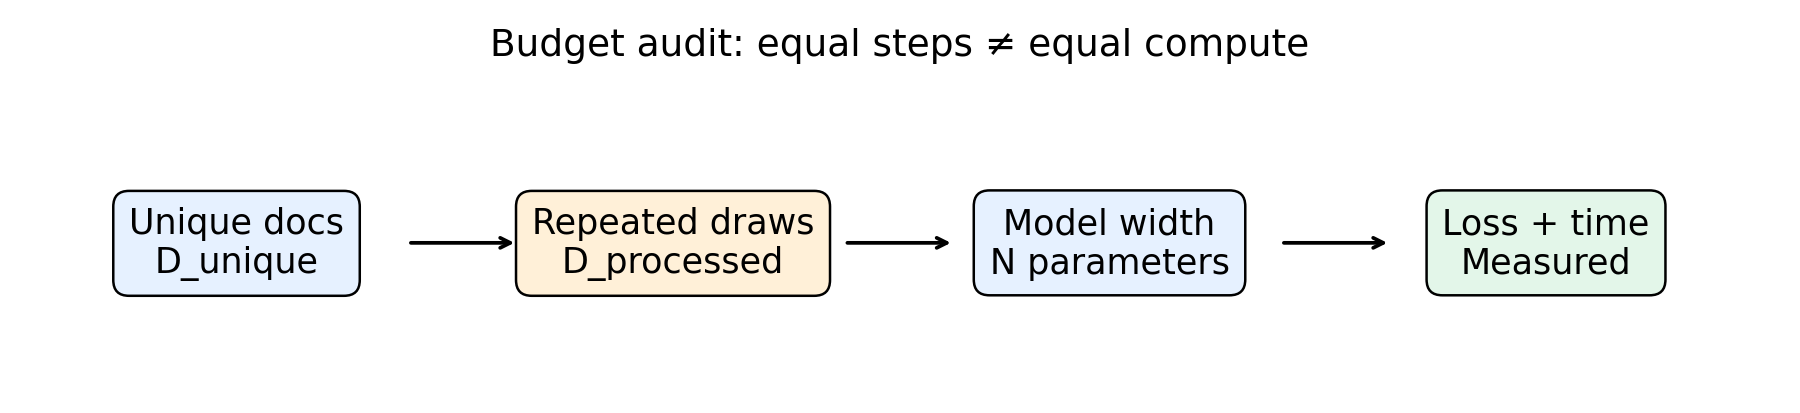

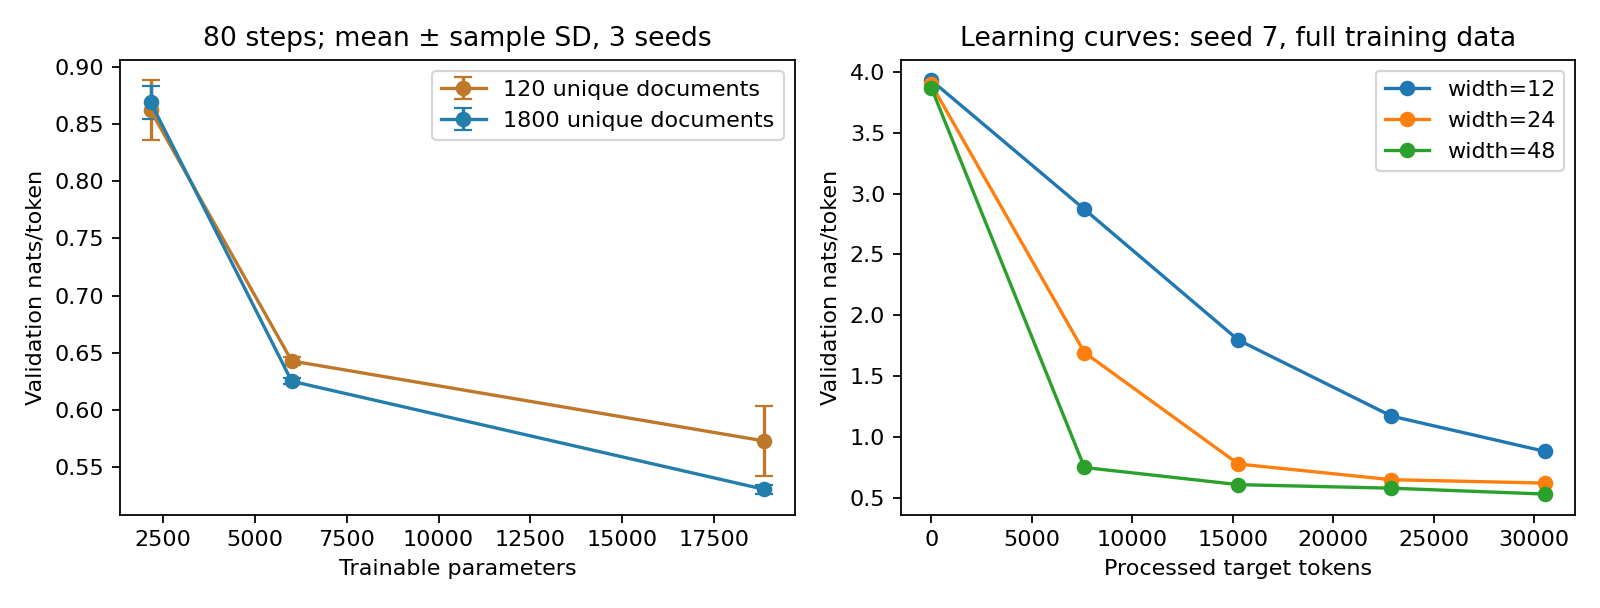

In [5]:
from IPython.display import display, Image
for p in sorted(pathlib.Path('figures').glob('*.png')):
    print(p.name)
    display(Image(filename=str(p)))

解释任务：逐项说明图中的控制变量、预算口径、失败对照和不能支持的结论。详细答案见answers.md。